# Nicheformer Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 04.12.2024
- Date of Last Modification: 04.12.2024 (by Sebastian Birk; sb75@sanger.ac.uk)

- Install the nicheformer conda environment ```../../envs/nicheformer.yaml```.
- For tokenization of the data, this notebook follows the notebook from https://github.com/theislab/nicheformer/blob/main/notebooks/tokenization/xenium_human_lung.ipynb.
- Download the pretrained model weights as described here https://github.com/theislab/nicheformer/blob/main/README.md and put them into the ```./nicheformer/data``` directory.

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import math
import os
from os.path import join

import anndata as ad
import pandas as pd
import numba
import numpy as np
import scanpy as sc
import pyarrow
import pyarrow.parquet as pq
from scipy.sparse import issparse
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from sklearn.utils import sparsefuncs
from tqdm import tqdm

from analysis_utils import *

### 1.2 Configure Paths

In [4]:
st_data_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/lustre/scratch126/cellgen/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'
nicheformer_folder_path = '/lustre/scratch126/cellgen/team361/sb75/nichejepa-reproducibility/analysis/benchmarking/nicheformer'

BASE_PATH = f'{nicheformer_folder_path}/data/model_means'
OUT_PATH = f'{nicheformer_folder_path}/data/adata_skin'

In [5]:
sys.path.append(f'{nicheformer_folder_path}/src') # to import modified nicheformer

In [6]:
from nicheformer._embeddings import get_embeddings_model

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/merlin/dtypes/mappings/tf.py:52: UserWarning: Tensorflow dtype mappings did not load successfully due to an error: No module named 'tensorflow'
  warn(f"Tensorflow dtype mappings did not load successfully due to an error: {exc.msg}")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/merlin/dtypes/mappings/triton.py:53: UserWarning: Triton dtype mappings did not load successfully due to an error: No module named 'tritonclient'
  warn(f"Triton dtype mappings did not load successfully due to an error: {exc.msg}")


### 1.3 Define Config

In [ ]:
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11', 'batch19', 'batch32']
sample_key = 'sample'
batch_key = 'batch'
niche_key = 'niche_type'
latent_cluster_key = 'predicted_niche'
latent_leiden_resolution = 0.85

In [8]:
modality_dict = {
    'dissociated': 3,
    'spatial': 4,}

specie_dict = {
    'human': 5,
    'Homo sapiens': 5,
    'Mus musculus': 6,
    'mouse': 6,}

technology_dict = {
    "merfish": 7,
    "MERFISH": 7,
    "cosmx": 8,
    "NanoString digital spatial profiling": 8,
    "Xenium": 9,
    "10x 5' v2": 10,
    "10x 3' v3": 11,
    "10x 3' v2": 12,
    "10x 5' v1": 13,
    "10x 3' v1": 14,
    "10x 3' transcription profiling": 15, 
    "10x transcription profiling": 15,
    "10x 5' transcription profiling": 16,
    "CITE-seq": 17, 
    "Smart-seq v4": 18,
}

### 1.4 Run Notebook Setup

In [9]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

In [10]:
os.makedirs(f'{artifacts_folder_path}/nicheformer', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/metrics', exist_ok=True)
os.makedirs(OUT_PATH, exist_ok=True)

### 1.5 Define Functions

In [11]:
def sf_normalize(X):
    X = X.copy()
    counts = np.array(X.sum(axis=1))
    # avoid zero devision error
    counts += counts == 0.
    # normalize to 10000. counts
    scaling_factor = 10000. / counts

    if issparse(X):
        sparsefuncs.inplace_row_scale(X, scaling_factor)
    else:
        np.multiply(X, scaling_factor.reshape((-1, 1)), out=X)

    return X

@numba.jit(nopython=True, nogil=True)
def _sub_tokenize_data(x: np.array, max_seq_len: int = -1, aux_tokens: int = 30):
    scores_final = np.empty((x.shape[0], max_seq_len if max_seq_len > 0 else x.shape[1]))
    for i, cell in enumerate(x):
        nonzero_mask = np.nonzero(cell)[0]    
        sorted_indices = nonzero_mask[np.argsort(-cell[nonzero_mask])][:max_seq_len] 
        sorted_indices = sorted_indices + aux_tokens # we reserve some tokens for padding etc (just in case)
        if max_seq_len:
            scores = np.zeros(max_seq_len, dtype=np.int32)
        else:
            scores = np.zeros_like(cell, dtype=np.int32)
        scores[:len(sorted_indices)] = sorted_indices.astype(np.int32)
        
        scores_final[i, :] = scores
        
    return scores_final


def tokenize_data(x: np.array, median_counts_per_gene: np.array, max_seq_len: int = None):
    """Tokenize the input gene vector to a vector of 32-bit integers."""

    x = np.nan_to_num(x) # is NaN values, fill with 0s
    x = sf_normalize(x)
    median_counts_per_gene += median_counts_per_gene == 0
    out = x / median_counts_per_gene.reshape((1, -1))

    scores_final = _sub_tokenize_data(out, 4096, 30)

    return scores_final.astype('i4')

## 2. Data

In [12]:
model = sc.read_h5ad(
    f"{BASE_PATH}/model.h5ad"
)

In [13]:
xenium_mean = np.load(
    f"{BASE_PATH}/xenium_mean_script.npy")

In [14]:
xenium_mean = np.nan_to_num(xenium_mean)
rounded_values = np.where((xenium_mean % 1) >= 0.5, np.ceil(xenium_mean), np.floor(xenium_mean))
xenium_mean = np.where(xenium_mean == 0, 1, rounded_values)
xenium_mean

array([1., 1., 1., ..., 1., 1., 1.])

In [15]:
# Load hold out skin samples and concatenate in one adata object
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            adata.var.index = adata.var['ensembl_id']
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.X = adata.layers['counts'] # TODO: temp, while raw counts are not stored in adata.X

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


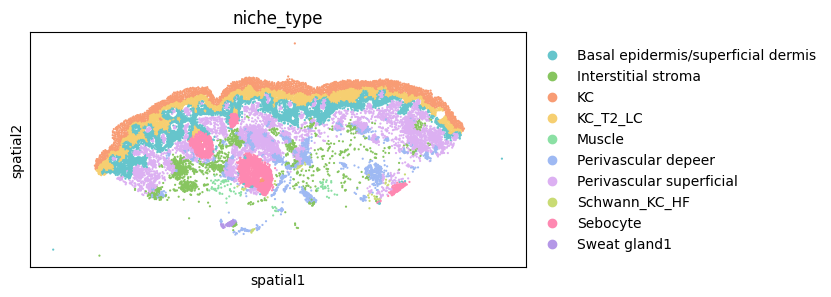

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


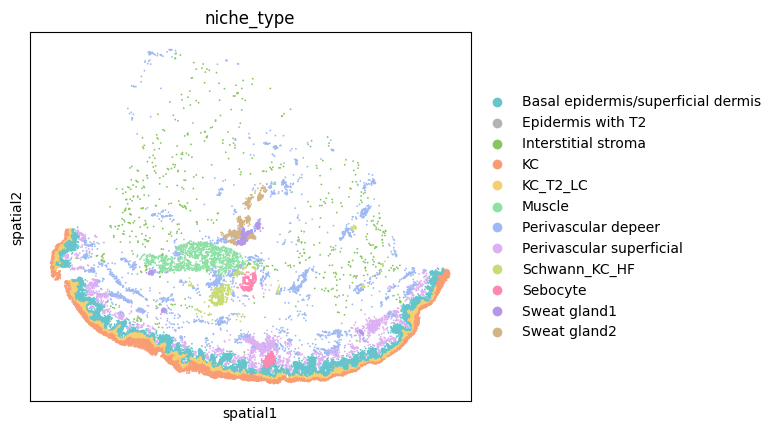

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


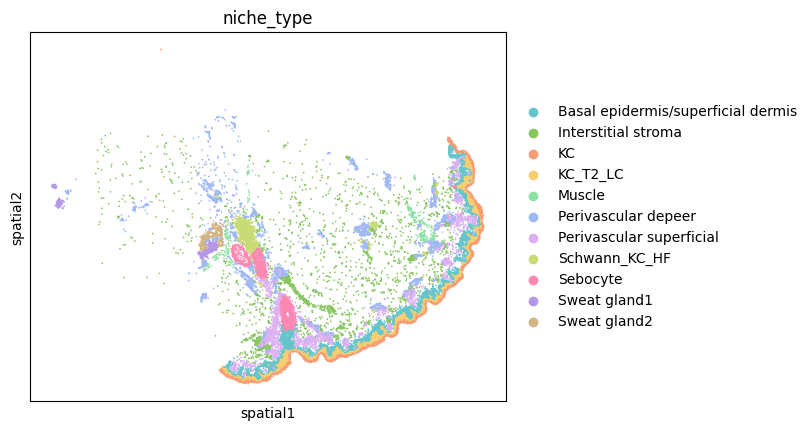

In [16]:
# Plot ground truth niches
spot_sizes = [20, 20, 20]
custom_palette_ground_truth = {niche: custom_palette[number] for niche, number in zip(
    adata.obs[niche_key].unique().tolist(), custom_palette)}

batch_ids = adata.obs[sample_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[sample_key] == batch_id]
    file_name = f'_ground_truth_niches_{batch_id}.svg'
    sc.pl.spatial(adata_batch,
                  color=niche_key,
                  palette=custom_palette_ground_truth,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [17]:
niche_mapping = {
    adata.obs['niche_type'].unique().tolist()[i]: i for i in range(len(adata.obs['niche_type'].unique().tolist()))}

adata.obs['niche'] = adata.obs[niche_key].apply(lambda x: niche_mapping[x])

In [18]:
# Next we concatenate the model and the merfish object to ensure they are in the 
# same order. This ensures we have the same gene ordering in the object.
adata_merged = ad.concat([model, adata], join='inner', axis=0)
adata_merged = adata_merged[1:] # dropping the first observation
adata_merged.obsm['spatial'] = adata.obsm['spatial']
adata = adata_merged.copy()
adata.X = adata.X.toarray()
del adata_merged # for memory efficiency

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/tmp/ipykernel_2520508/2653454371.py:5: ImplicitModificationWarning: Setting element `.obsm['spatial']` of view, initializing view as actual.
  adata_merged.obsm['spatial'] = adata.obsm['spatial']


In [19]:
gene_avail_idx = [gene in adata.var.index.tolist() for gene in model.var.index.tolist()]
xenium_mean = xenium_mean[gene_avail_idx]

In [20]:
batch_mapping = {
    list(set([ind.split('_', 1)[1] for ind in adata.obs.index.tolist()]))[i]: i
    for i in range(len(list(set([ind.split('_', 1)[1]
                                 for ind in adata.obs.index.tolist()]))))}

adata.obs['assay'] = 'Xenium'
adata.obs['organism'] = 'human'
adata.obs['batch'] = [batch_mapping[ind.split('_', 1)[1]] for ind in adata.obs.index.tolist()]
adata.obs['modality'] = 'spatial'
adata.obs['specie'] = adata.obs.organism

adata.obs.replace({'specie': specie_dict}, inplace=True)
adata.obs.replace({'modality': modality_dict}, inplace=True)
adata.obs.replace({'assay': technology_dict}, inplace=True)

In [21]:
# dropping the index as the original index can create issues 
adata.obs.reset_index(drop=True, inplace=True)

In [22]:
obs_adata = adata.obs
print('n_obs: ', obs_adata.shape[0])
N_BATCHES = math.ceil(obs_adata.shape[0] / 10_000)
print('N_BATCHES: ', N_BATCHES)
batch_indices = np.array_split(obs_adata.index, N_BATCHES)
chunk_len = len(batch_indices[0])
print('chunk_len: ', chunk_len)

n_obs:  53655
N_BATCHES:  6
chunk_len:  8943


In [23]:
xenium_mean.shape

(4943,)

In [24]:
obs_adata = obs_adata.reset_index().rename(columns={'index':'idx'})
obs_adata['idx'] = obs_adata['idx'].astype('i8')

In [25]:
for batch in tqdm(range(N_BATCHES)):
    obs_tokens = obs_adata.iloc[batch*chunk_len:chunk_len*(batch+1)].copy()
    tokenized = tokenize_data(adata.X[batch*chunk_len:chunk_len*(batch+1)], xenium_mean, 4096)

    obs_tokens = obs_tokens[['assay', 'specie', 'modality', 'niche', 'idx']]
    # concatenate dataframes
    
    obs_tokens['X'] = [tokenized[i, :] for i in range(tokenized.shape[0])]

    # mix spatial and dissociate data
    obs_tokens = obs_tokens.sample(frac=1)
    
    total_table = pyarrow.Table.from_pandas(obs_tokens)
    
    pq.write_table(total_table, f'{join(OUT_PATH)}/test/tokens-{batch}.parquet',
                    row_group_size=1024,)


00%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:14<00:00,  2.41s/it]

In [44]:
# Check whether everything looks correct
pd.read_parquet(f'{join(OUT_PATH)}/test/tokens-{batch}.parquet').head(2)

,assay,specie,modality,niche,idx,X
53447,9,5,4,8,53447,"[4257, 2289, 4150, 2438, 1568, 2311, 1833, 207..."
47760,9,5,4,5,47760,"[4150, 682, 2666, 3049, 4660, 2990, 1380, 4275..."


## 3. Model

### 3.1 Zero-shot Niche Identification

In [ ]:
# Run model zero-shot
config = {
    'checkpoint_path': f'{nicheformer_folder_path}/data/nicheformer.ckpt',
    'baseline': False,
    'freeze': False,
    'extract_layers': [11],
    'reinit_layers': None,
    'function_layers': 'mean',
    'extractor': False,
    'batch_size': 12,
    'lr': 1e-4,
    'warmup': 1,
    'max_epochs': 50000,
    'pool': 'mean',
    'n_classes': 17,
    'dim_prediction': 1, 
    'supervised_task': 'niche_classification',
    'regress_distribution': False,
    'predict_density': False,
    'ignore_zeros': False,
    'baseline': False,
    'organ': 'skin',
    'label': 'niche',
    }

get_embeddings_model(folder=f'{artifacts_folder_path}/benchmarking/nicheformer',
                     data_path=OUT_PATH,
                     config=config)

In [77]:
# Load embeddings
embeddings = np.load(f'{artifacts_folder_path}/benchmarking/nicheformer/embeddings.npy')

# Load metadata
metadata = pd.read_csv(f'{artifacts_folder_path}/benchmarking/nicheformer/metadata_embeddings.csv')

adata.obsm['emb'] = embeddings[np.argsort(metadata['index'].values)]

In [102]:
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='emb',
                #method='rapids',
                key_added='emb')
sc.tl.umap(adata,
           neighbors_key='emb',
           #method='rapids'
          )
sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)
#sc.pl.umap(adata,
#           color='niche')

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


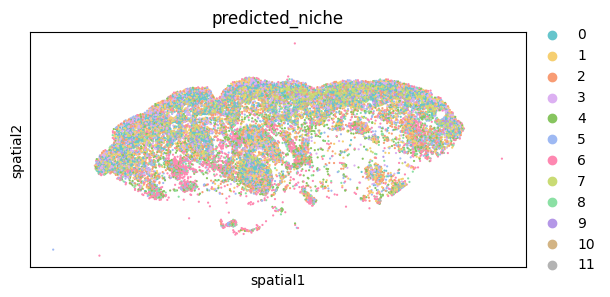

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


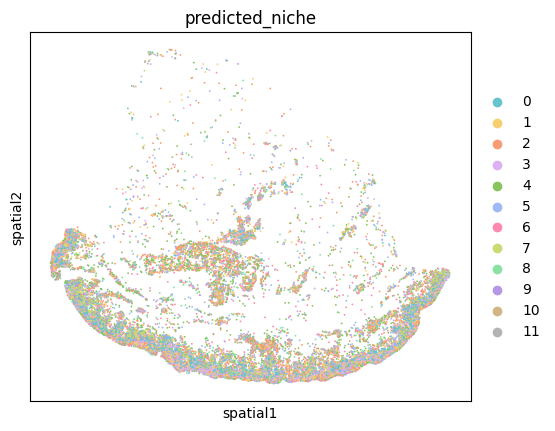

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nicheformer/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


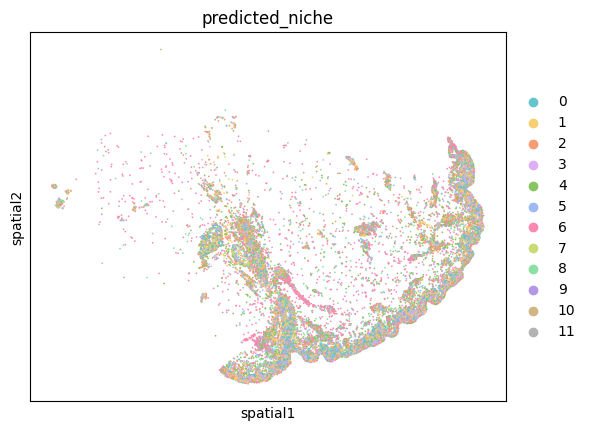

In [103]:
# Plot predicted niches
spot_sizes = [20, 20, 20]

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'_nicheformer_niches_{batch_id}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [104]:
# Compute metrics
labels = adata.obs['niche']
labels_pred = adata.obs[latent_cluster_key]

nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)

print(f'NMI is {nmi}. ARI is {ari}.')

NMI is 0.10967853006742. ARI is 0.0519126999900914.


In [105]:
metrics_df = pd.DataFrame({'Metric': ['NMI', 'ARI'], 'Value': [nmi, ari]})
metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/metrics/nicheformer.csv', index=False)

In [ ]:
/